# Exercise 1: Multi-Layer Perceptron on CIFAR-10

**Aim.** Train a fully connected Multi-Layer Perceptron (MLP) with exactly three trainable layers to classify CIFAR-10 images into 10 classes. The training and validation behaviour is tracked over 30 epochs, and the best checkpoint by validation loss is evaluated once on the held-out test set. This setup acts as the fixed baseline that Exercises 2 to 4 reuse.

**How to run.** Install the packages in `requirements.txt`, then use *Kernel > Restart Kernel and Run All*. CIFAR-10 is downloaded to `data/` on the first run, and all outputs are written to `outputs/`.

## 1. Setup: imports, seed, device, paths

In [1]:
import json
import random
import time
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import classification_report, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

In [2]:
SEED = 42
BATCH_SIZE = 128
EPOCHS = 30
SELECTION_EPOCHS = 10
TRAIN_SIZE = 45_000
VAL_SIZE = 5_000
NUM_WORKERS = 2
EXPECTED_PARAMETER_COUNT = 1_707_274
FIGURE_DPI = 300

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
HISTORY_PATH = OUTPUT_DIR / "exercise1 history.csv"
METRICS_PATH = OUTPUT_DIR / "exercise1 metrics.json"
CONFIG_PATH = OUTPUT_DIR / "exercise1 config.json"
CHECKPOINT_PATH = OUTPUT_DIR / "exercise1 best model.pt"

for directory in (DATA_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None

print(f"PyTorch {torch.__version__} | device: {DEVICE}")
if GPU_NAME:
    print(f"GPU: {GPU_NAME}")

PyTorch 2.15.0+cpu | device: cpu


In [4]:
def save_figure(figure, file_name):
    figure.savefig(FIGURE_DIR / file_name, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()

## 2. Data loading, split, and normalisation

Training images: 50,000
Test images : 10,000 
The training partition: 45,000 training, 5,000 validation images with a seeded generator 

In [5]:
try:
    train_full_dataset = datasets.CIFAR10(DATA_DIR, train=True, download=True)
    test_dataset = datasets.CIFAR10(DATA_DIR, train=False, download=True)
except Exception as error:
    raise RuntimeError(
        f"Could not download or load CIFAR-10 into '{DATA_DIR}'. Check the internet connection, "
        "or place the extracted 'cifar-10-batches-py' folder in that directory and rerun."
    ) from error

CLASS_NAMES = train_full_dataset.classes
TARGETS = np.array(train_full_dataset.targets)

In [6]:
train_subset, val_subset = random_split(
    train_full_dataset, [TRAIN_SIZE, VAL_SIZE], generator=torch.Generator().manual_seed(SEED)
)

Normalisation statistics are computed on the raw pixels of the 45,000 training images only. Both subsets are views of the same underlying dataset object, so setting its transform once makes training and validation use the identical `ToTensor()` then `Normalize(mean, std)` pipeline, and the test set receives the same transform. No augmentation is used because this is the clean baseline.

In [7]:
# Statistics come from the training subset only, so no validation or test information leaks into preprocessing.
train_pixels = train_full_dataset.data[train_subset.indices]
CHANNEL_MEAN = [float(train_pixels[..., channel].mean() / 255) for channel in range(3)]
CHANNEL_STD = [float(train_pixels[..., channel].std() / 255) for channel in range(3)]

NORMALISE_TRANSFORM = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CHANNEL_MEAN, CHANNEL_STD),
])
train_full_dataset.transform = NORMALISE_TRANSFORM
test_dataset.transform = NORMALISE_TRANSFORM

pd.DataFrame({"mean": CHANNEL_MEAN, "std": CHANNEL_STD}, index=["red", "green", "blue"]).round(4)

,mean,std
red,0.4917,0.2471
green,0.4823,0.2435
blue,0.4467,0.2616


In [8]:
LOADER_SETTINGS = dict(
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=True
)
train_loader = DataLoader(train_subset, shuffle=True, **LOADER_SETTINGS)
val_loader = DataLoader(val_subset, shuffle=False, **LOADER_SETTINGS)

## 3. Data sanity checks

One raw training image per class confirms that labels line up with image content, and the class counts confirm the random split is close to balanced.

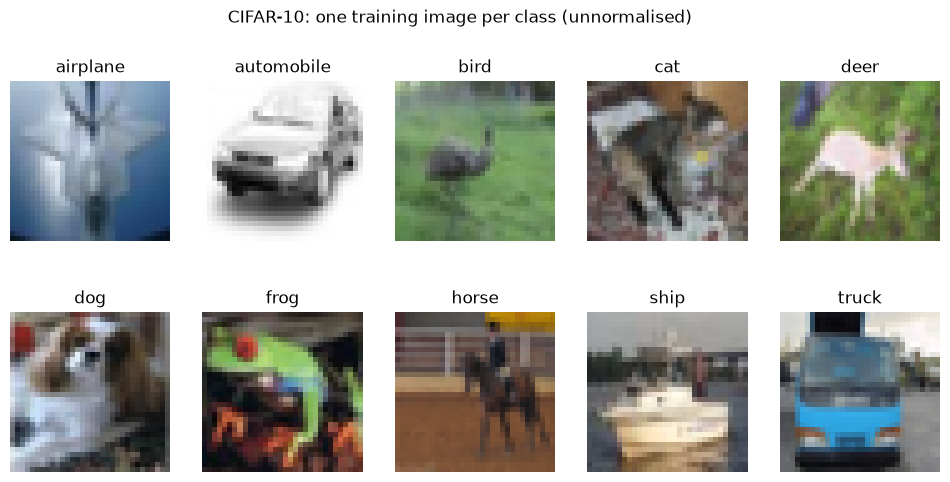

In [9]:
first_index_per_class = {}
for index in train_subset.indices:
    first_index_per_class.setdefault(int(TARGETS[index]), index)
    if len(first_index_per_class) == len(CLASS_NAMES):
        break

figure, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for label, axis in enumerate(axes.flat):
    axis.imshow(train_full_dataset.data[first_index_per_class[label]])
    axis.set_title(CLASS_NAMES[label])
    axis.axis("off")
figure.suptitle("CIFAR-10: one training image per class (unnormalised)")
save_figure(figure, "exercise1 sample images.png")

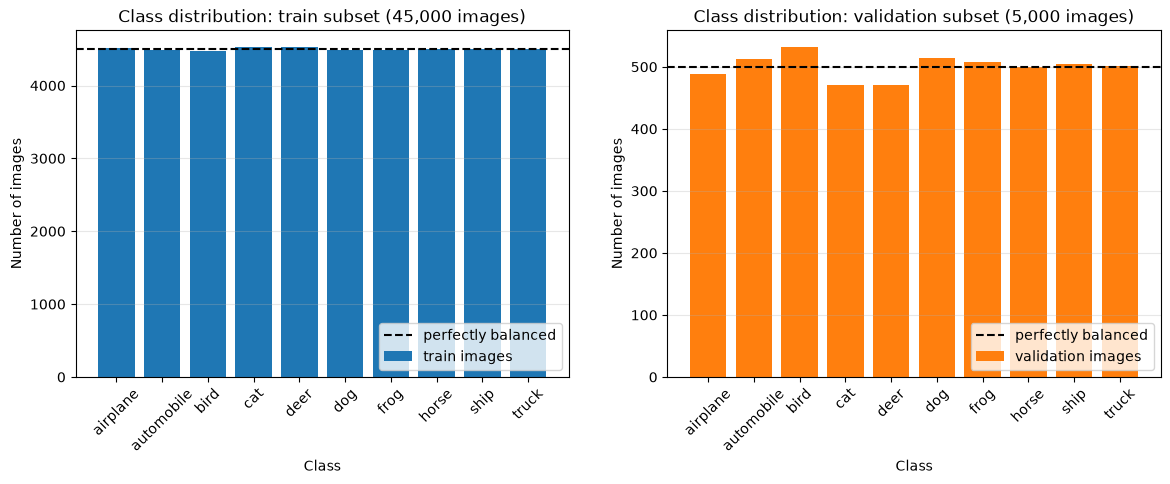

,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
train,4512,4488,4468,4529,4529,4486,4493,4500,4496,4499
validation,488,512,532,471,471,514,507,500,504,501


In [10]:
class_counts = pd.DataFrame(
    {
        "train": np.bincount(TARGETS[train_subset.indices], minlength=len(CLASS_NAMES)),
        "validation": np.bincount(TARGETS[val_subset.indices], minlength=len(CLASS_NAMES)),
    },
    index=CLASS_NAMES,
)

figure, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for axis, (split_name, counts), colour in zip(axes, class_counts.items(), ["tab:blue", "tab:orange"]):
    axis.bar(CLASS_NAMES, counts, color=colour, label=f"{split_name} images")
    axis.axhline(counts.sum() / len(CLASS_NAMES), color="black", linestyle="--", label="perfectly balanced")
    axis.set_title(f"Class distribution: {split_name} subset ({counts.sum():,} images)")
    axis.set_xlabel("Class")
    axis.set_ylabel("Number of images")
    axis.tick_params(axis="x", rotation=45)
    axis.grid(axis="y", alpha=0.3)
    axis.legend(loc="lower right")
save_figure(figure, "exercise1 class distribution.png")

class_counts.T

## 4. Model definition and parameter count

The MLP flattens each 3 x 32 x 32 image to 3,072 values and passes it through three `Linear` layers, which are the only trainable layers. ReLU is used in the hidden layers because it is cheap and avoids the vanishing gradients of sigmoid or tanh. BatchNorm and Dropout are left out on purpose: BatchNorm has its own trainable parameters, and this is the unregularised baseline.

In [11]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            # Outputs raw logits: CrossEntropyLoss applies log-softmax internally.
            nn.Linear(256, 10),
        )

    def forward(self, images):
        return self.network(images)

In [12]:
def count_trainable_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


model = MLP().to(DEVICE)
PARAMETER_COUNT = count_trainable_parameters(model)
assert PARAMETER_COUNT == EXPECTED_PARAMETER_COUNT, f"Expected {EXPECTED_PARAMETER_COUNT:,}, got {PARAMETER_COUNT:,}"

print(model)
print(f"Trainable parameters: {PARAMETER_COUNT:,}")

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)
Trainable parameters: 1,707,274


In [13]:
pd.DataFrame(
    [
        {
            "layer": name,
            "shape": f"{module.in_features} -> {module.out_features}",
            "weights": module.weight.numel(),
            "biases": module.bias.numel(),
            "parameters": module.weight.numel() + module.bias.numel(),
        }
        for name, module in model.named_modules()
        if isinstance(module, nn.Linear)
    ]
)

,layer,shape,weights,biases,parameters
0,network.1,3072 -> 512,1572864,512,1573376
1,network.3,512 -> 256,131072,256,131328
2,network.5,256 -> 10,2560,10,2570


## 5. Training and evaluation functions

Losses are weighted by batch size so the epoch loss is the true mean over all samples, which matters because the last batch is smaller. Accuracies are reported as percentages. `train_model` is reused for both the optimiser check and the main run, and only saves a checkpoint when a path is given.

In [14]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)
    return total_loss / total_samples, 100 * total_correct / total_samples


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, total_samples = 0.0, 0
    all_predictions, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * labels.size(0)
            total_samples += labels.size(0)
            all_predictions.append(logits.argmax(dim=1).cpu())
            all_labels.append(labels.cpu())
    predictions = torch.cat(all_predictions).numpy()
    labels = torch.cat(all_labels).numpy()
    accuracy = 100 * (predictions == labels).mean()
    return total_loss / total_samples, accuracy, predictions, labels

In [15]:
def train_model(model, optimizer, criterion, train_loader, val_loader, epochs, run_name, checkpoint_path=None):
    history = []
    best_val_loss, best_epoch = float("inf"), 0
    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()
        train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_loss, val_accuracy, _, _ = evaluate(model, val_loader, criterion, DEVICE)
        epoch_seconds = time.perf_counter() - epoch_start

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "epoch_seconds": epoch_seconds,
        })
        improved = val_loss < best_val_loss
        if improved:
            best_val_loss, best_epoch = val_loss, epoch
            if checkpoint_path is not None:
                torch.save(model.state_dict(), checkpoint_path)
        print(
            f"[{run_name}] epoch {epoch:2d}/{epochs} | train loss {train_loss:.4f} acc {train_accuracy:5.2f}% | "
            f"val loss {val_loss:.4f} acc {val_accuracy:5.2f}% | {epoch_seconds:5.1f}s{' *' if improved else ''}"
        )
    return pd.DataFrame(history), best_epoch

## 6. Optimiser selection on validation

Cross-entropy is the standard loss for single-label multi-class classification. Three optimiser settings are each trained for 10 epochs from identical initial weights, and the one with the lowest validation loss is selected. Only the validation set is used here; the test set plays no part in this choice.

In [16]:
criterion = nn.CrossEntropyLoss()

OPTIMISER_CANDIDATES = {
    "Adam lr=1e-3": (torch.optim.Adam, {"lr": 1e-3}),
    "Adam lr=1e-4": (torch.optim.Adam, {"lr": 1e-4}),
    "SGD lr=0.01 momentum=0.9": (torch.optim.SGD, {"lr": 0.01, "momentum": 0.9}),
}

selection_histories = {}
for candidate_name, (optimiser_class, optimiser_settings) in OPTIMISER_CANDIDATES.items():
    set_seed(SEED)
    candidate_model = MLP().to(DEVICE)
    candidate_optimiser = optimiser_class(candidate_model.parameters(), **optimiser_settings)
    selection_histories[candidate_name], _ = train_model(
        candidate_model, candidate_optimiser, criterion, train_loader, val_loader, SELECTION_EPOCHS, candidate_name
    )

[Adam lr=1e-3] epoch  1/10 | train loss 1.6529 acc 41.35% | val loss 1.5369 acc 46.70% |  28.8s *


[Adam lr=1e-3] epoch  2/10 | train loss 1.4438 acc 49.01% | val loss 1.4891 acc 48.10% |   6.7s *


[Adam lr=1e-3] epoch  3/10 | train loss 1.3363 acc 52.84% | val loss 1.4213 acc 49.98% |   6.7s *


[Adam lr=1e-3] epoch  4/10 | train loss 1.2401 acc 56.27% | val loss 1.3759 acc 52.06% |   6.6s *


[Adam lr=1e-3] epoch  5/10 | train loss 1.1566 acc 59.12% | val loss 1.3732 acc 51.96% |   6.8s *


[Adam lr=1e-3] epoch  6/10 | train loss 1.0821 acc 61.51% | val loss 1.4157 acc 51.98% |   6.8s


... (20 outputs left out)

[SGD lr=0.01 momentum=0.9] epoch  7/10 | train loss 1.0206 acc 64.23% | val loss 1.3507 acc 53.02% |   6.4s *


[SGD lr=0.01 momentum=0.9] epoch  8/10 | train loss 0.9525 acc 66.64% | val loss 1.3599 acc 53.94% |   6.3s


[SGD lr=0.01 momentum=0.9] epoch  9/10 | train loss 0.8865 acc 68.86% | val loss 1.3950 acc 53.10% |   6.4s


[SGD lr=0.01 momentum=0.9] epoch 10/10 | train loss 0.8298 acc 70.93% | val loss 1.4937 acc 52.20% |   6.4s


In [17]:
selection_summary = pd.DataFrame(
    [
        {
            "optimiser": candidate_name,
            "best val loss": history["val_loss"].min(),
            "best epoch": int(history.loc[history["val_loss"].idxmin(), "epoch"]),
            "val accuracy at best epoch (%)": history.loc[history["val_loss"].idxmin(), "val_accuracy"],
            "highest val accuracy (%)": history["val_accuracy"].max(),
        }
        for candidate_name, history in selection_histories.items()
    ]
).set_index("optimiser")

CHOSEN_OPTIMISER = selection_summary["best val loss"].idxmin()
CHOSEN_OPTIMISER_CLASS, CHOSEN_OPTIMISER_SETTINGS = OPTIMISER_CANDIDATES[CHOSEN_OPTIMISER]
print(f"Chosen optimiser: {CHOSEN_OPTIMISER}")
selection_summary.round(4)

Chosen optimiser: Adam lr=1e-4


,best val loss,best epoch,val accuracy at best epoch (%),highest val accuracy (%)
optimiser,,,,
Adam lr=1e-3,1.3732,5,51.96,52.64
Adam lr=1e-4,1.3449,7,52.34,53.94
SGD lr=0.01 momentum=0.9,1.3507,7,53.02,53.94


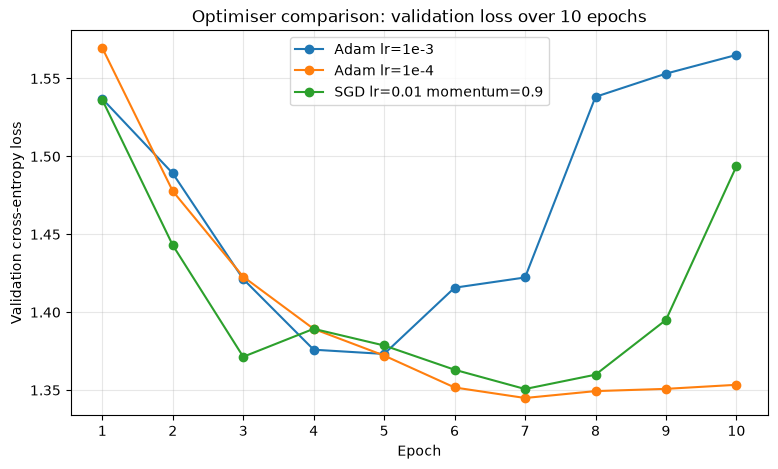

In [18]:
figure, axis = plt.subplots(figsize=(9, 5))
for candidate_name, history in selection_histories.items():
    axis.plot(history["epoch"], history["val_loss"], marker="o", label=candidate_name)
axis.set_title(f"Optimiser comparison: validation loss over {SELECTION_EPOCHS} epochs")
axis.set_xlabel("Epoch")
axis.set_ylabel("Validation cross-entropy loss")
axis.set_xticks(range(1, SELECTION_EPOCHS + 1))
axis.grid(alpha=0.3)
axis.legend()
save_figure(figure, "exercise1 optimiser comparison.png")

The fixed configuration, including the validation indices and the selected optimiser, is saved so Exercises 2 to 4 can reuse exactly the same setup.

In [19]:
experiment_config = {
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "optimiser_selection_epochs": SELECTION_EPOCHS,
    "train_size": TRAIN_SIZE,
    "val_size": VAL_SIZE,
    "num_workers": NUM_WORKERS,
    "loss": "CrossEntropyLoss",
    "architecture": "Flatten -> Linear(3072, 512) -> ReLU -> Linear(512, 256) -> ReLU -> Linear(256, 10)",
    "normalisation": {"mean": CHANNEL_MEAN, "std": CHANNEL_STD},
    "optimiser": {
        "name": CHOSEN_OPTIMISER,
        "class": CHOSEN_OPTIMISER_CLASS.__name__,
        "settings": CHOSEN_OPTIMISER_SETTINGS,
    },
    "validation_indices": [int(index) for index in val_subset.indices],
}
with CONFIG_PATH.open("w") as config_file:
    json.dump(experiment_config, config_file, indent=2)

## 7. Main training run

A fresh model is trained for 30 epochs with the selected optimiser. The weights are saved whenever validation loss improves (marked with `*`), so the final evaluation uses the epoch with the lowest validation loss rather than the last epoch.

In [20]:
set_seed(SEED)
model = MLP().to(DEVICE)
optimizer = CHOSEN_OPTIMISER_CLASS(model.parameters(), **CHOSEN_OPTIMISER_SETTINGS)

training_start = time.perf_counter()
history, BEST_EPOCH = train_model(
    model, optimizer, criterion, train_loader, val_loader, EPOCHS, "main", checkpoint_path=CHECKPOINT_PATH
)
TOTAL_TRAINING_SECONDS = time.perf_counter() - training_start

history.to_csv(HISTORY_PATH, index=False)

[main] epoch  1/30 | train loss 1.7155 acc 39.74% | val loss 1.5696 acc 45.24% |   7.0s *


[main] epoch  2/30 | train loss 1.4836 acc 48.08% | val loss 1.4777 acc 49.24% |   7.1s *


[main] epoch  3/30 | train loss 1.3842 acc 51.64% | val loss 1.4228 acc 50.84% |   7.1s *


[main] epoch  4/30 | train loss 1.3035 acc 54.96% | val loss 1.3893 acc 51.72% |   6.9s *


[main] epoch  5/30 | train loss 1.2403 acc 57.09% | val loss 1.3722 acc 52.70% |   7.2s *


[main] epoch  6/30 | train loss 1.1794 acc 59.43% | val loss 1.3517 acc 52.76% |   7.1s *


... (20 outputs left out)

[main] epoch 27/30 | train loss 0.3804 acc 88.72% | val loss 1.7082 acc 52.56% |   7.0s


[main] epoch 28/30 | train loss 0.3530 acc 89.51% | val loss 1.7371 acc 53.70% |   7.0s


[main] epoch 29/30 | train loss 0.3343 acc 90.15% | val loss 1.7848 acc 53.00% |   6.9s


[main] epoch 30/30 | train loss 0.3068 acc 91.19% | val loss 1.8546 acc 52.66% |   6.9s


## 8. Training curves

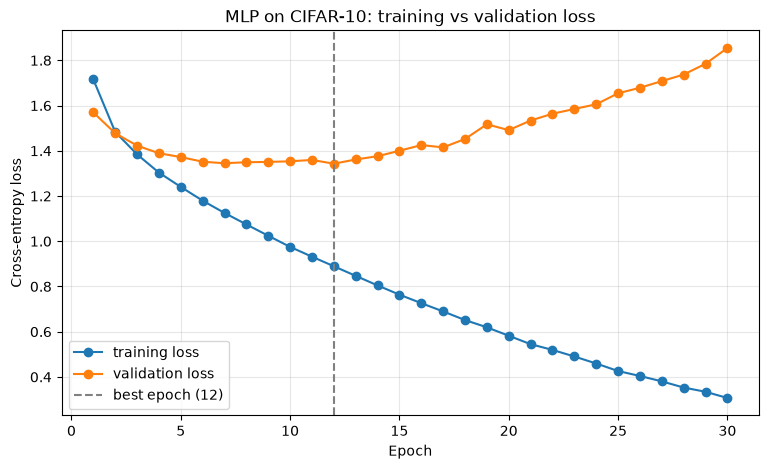

In [21]:
figure, axis = plt.subplots(figsize=(9, 5))
axis.plot(history["epoch"], history["train_loss"], marker="o", label="training loss")
axis.plot(history["epoch"], history["val_loss"], marker="o", label="validation loss")
axis.axvline(BEST_EPOCH, color="grey", linestyle="--", label=f"best epoch ({BEST_EPOCH})")
axis.set_title("MLP on CIFAR-10: training vs validation loss")
axis.set_xlabel("Epoch")
axis.set_ylabel("Cross-entropy loss")
axis.grid(alpha=0.3)
axis.legend()
save_figure(figure, "exercise1 loss curves.png")

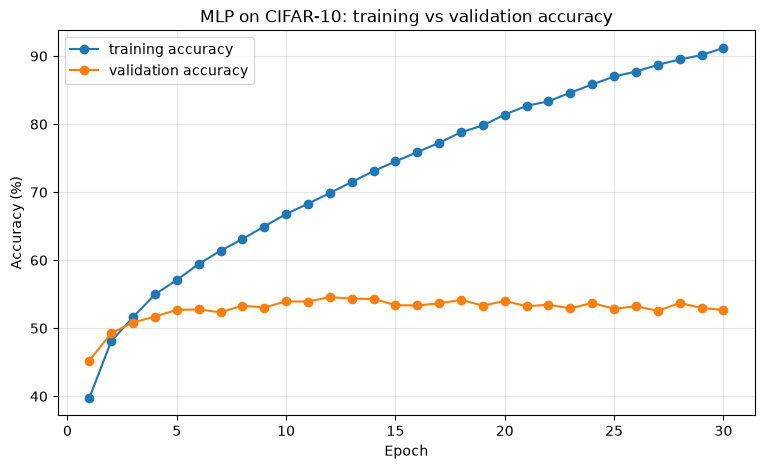

In [22]:
figure, axis = plt.subplots(figsize=(9, 5))
axis.plot(history["epoch"], history["train_accuracy"], marker="o", label="training accuracy")
axis.plot(history["epoch"], history["val_accuracy"], marker="o", label="validation accuracy")
axis.set_title("MLP on CIFAR-10: training vs validation accuracy")
axis.set_xlabel("Epoch")
axis.set_ylabel("Accuracy (%)")
axis.grid(alpha=0.3)
axis.legend()
save_figure(figure, "exercise1 accuracy curves.png")

## 9. Final evaluation on the test set

The best checkpoint is loaded and evaluated on all three splits. This is the only place where the test set is passed through the model.

In [23]:
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Best checkpoint not found at '{CHECKPOINT_PATH}'. Run the main training section first.")

model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True))
test_loader = DataLoader(test_dataset, shuffle=False, **LOADER_SETTINGS)

train_loss, train_accuracy, _, _ = evaluate(model, train_loader, criterion, DEVICE)
val_loss, val_accuracy, _, _ = evaluate(model, val_loader, criterion, DEVICE)
test_loss, test_accuracy, test_predictions, test_labels = evaluate(model, test_loader, criterion, DEVICE)
ACCURACY_GAP = train_accuracy - test_accuracy

final_results = pd.DataFrame(
    {"loss": [train_loss, val_loss, test_loss], "accuracy (%)": [train_accuracy, val_accuracy, test_accuracy]},
    index=["train", "validation", "test"],
)
print(f"Best epoch: {BEST_EPOCH} | train minus test accuracy gap: {ACCURACY_GAP:.2f} percentage points")
final_results.round(4)

Best epoch: 12 | train minus test accuracy gap: 19.64 percentage points


,loss,accuracy (%)
train,0.8078,73.6956
validation,1.3429,54.5800
test,1.3414,54.0600


In [24]:
pd.DataFrame(
    classification_report(test_labels, test_predictions, target_names=CLASS_NAMES, digits=4, output_dict=True)
).T.round(4)

,precision,recall,f1-score,support
airplane,0.6253,0.6190,0.6221,1000.0000
automobile,0.6756,0.6310,0.6525,1000.0000
bird,0.4499,0.4220,0.4355,1000.0000
cat,0.3753,0.3370,0.3551,1000.0000
deer,0.4465,0.4630,0.4546,1000.0000
dog,0.4355,0.4290,0.4322,1000.0000
frog,0.6058,0.5870,0.5962,1000.0000
horse,0.5611,0.6290,0.5931,1000.0000
ship,0.6621,0.6840,0.6729,1000.0000
truck,0.5525,0.6050,0.5776,1000.0000


In [25]:
test_confusion = confusion_matrix(test_labels, test_predictions)
per_class_accuracy = pd.DataFrame(
    {
        "correct": np.diag(test_confusion),
        "total": test_confusion.sum(axis=1),
        "accuracy (%)": 100 * np.diag(test_confusion) / test_confusion.sum(axis=1),
    },
    index=CLASS_NAMES,
).sort_values("accuracy (%)", ascending=False)
per_class_accuracy.round(2)

,correct,total,accuracy (%)
ship,684,1000,68.4
automobile,631,1000,63.1
horse,629,1000,62.9
airplane,619,1000,61.9
truck,605,1000,60.5
frog,587,1000,58.7
deer,463,1000,46.3
dog,429,1000,42.9
bird,422,1000,42.2
cat,337,1000,33.7


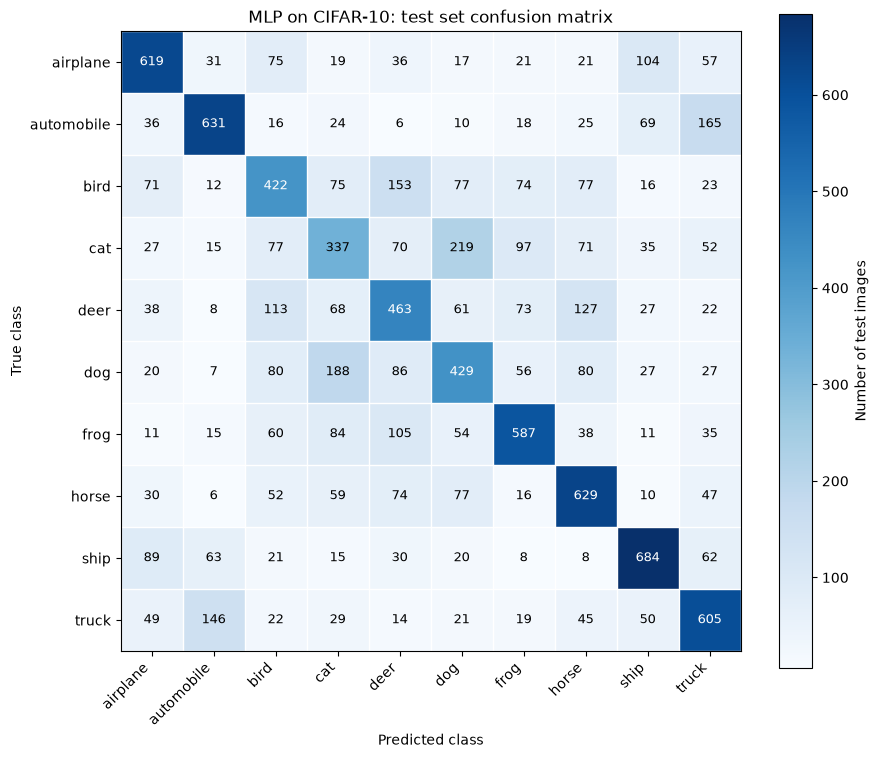

In [26]:
figure, axis = plt.subplots(figsize=(10, 8.5))
heatmap = axis.imshow(test_confusion, cmap="Blues")
figure.colorbar(heatmap, ax=axis, label="Number of test images")
colour_threshold = test_confusion.max() / 2
for true_index, predicted_index in np.ndindex(test_confusion.shape):
    count = test_confusion[true_index, predicted_index]
    axis.text(
        predicted_index, true_index, count, ha="center", va="center",
        color="white" if count > colour_threshold else "black", fontsize=9,
    )
axis.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
axis.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
axis.set_xticks(np.arange(-0.5, len(CLASS_NAMES)), minor=True)
axis.set_yticks(np.arange(-0.5, len(CLASS_NAMES)), minor=True)
axis.grid(which="minor", color="white", linewidth=1)
axis.tick_params(which="minor", length=0)
axis.set_title("MLP on CIFAR-10: test set confusion matrix")
axis.set_xlabel("Predicted class")
axis.set_ylabel("True class")
save_figure(figure, "exercise1 confusion matrix.png")

Confusions are counted in both directions for each pair of classes, so a pair's total is how often the model mixed up those two classes.

In [27]:
confused_pairs = pd.DataFrame(
    [
        {
            "class A": CLASS_NAMES[first],
            "class B": CLASS_NAMES[second],
            "A predicted as B": int(test_confusion[first, second]),
            "B predicted as A": int(test_confusion[second, first]),
            "total confusions": int(test_confusion[first, second] + test_confusion[second, first]),
        }
        for first, second in combinations(range(len(CLASS_NAMES)), 2)
    ]
)
TOP_CONFUSED_PAIRS = confused_pairs.nlargest(3, "total confusions").reset_index(drop=True)
TOP_CONFUSED_PAIRS

,class A,class B,A predicted as B,B predicted as A,total confusions
0,cat,dog,219,188,407
1,automobile,truck,165,146,311
2,bird,deer,153,113,266


In [28]:
metrics = {
    "train": {"loss": train_loss, "accuracy": train_accuracy},
    "validation": {"loss": val_loss, "accuracy": val_accuracy},
    "test": {"loss": test_loss, "accuracy": test_accuracy},
    "train_minus_test_accuracy_gap": ACCURACY_GAP,
    "best_epoch": BEST_EPOCH,
    "parameter_count": PARAMETER_COUNT,
    "chosen_optimiser": CHOSEN_OPTIMISER,
    "total_training_seconds": TOTAL_TRAINING_SECONDS,
    "device": str(DEVICE),
    "gpu_name": GPU_NAME,
    "per_class_test_accuracy": per_class_accuracy["accuracy (%)"].to_dict(),
    "top_confused_pairs": TOP_CONFUSED_PAIRS.to_dict(orient="records"),
}
with METRICS_PATH.open("w") as metrics_file:
    json.dump(metrics, metrics_file, indent=2, default=float)

## 10. Results summary

The summary below is generated from `outputs/exercise1 metrics.json`, so the numbers always match the saved outputs.

In [29]:
saved_metrics = json.loads(METRICS_PATH.read_text())
top_pairs_text = ", ".join(
    f"{pair['class A']} / {pair['class B']} ({pair['total confusions']})" for pair in saved_metrics["top_confused_pairs"]
)
display(Markdown(
    f"""- **Model:** three-layer MLP with {saved_metrics['parameter_count']:,} trainable parameters, trained on {saved_metrics['device']}.
- **Optimiser:** {saved_metrics['chosen_optimiser']} (lowest validation loss in the {SELECTION_EPOCHS}-epoch check).
- **Best epoch:** {saved_metrics['best_epoch']} of {EPOCHS}; main run took {saved_metrics['total_training_seconds'] / 60:.1f} minutes.
- **Accuracy:** train {saved_metrics['train']['accuracy']:.2f}%, validation {saved_metrics['validation']['accuracy']:.2f}%, test {saved_metrics['test']['accuracy']:.2f}%.
- **Loss:** train {saved_metrics['train']['loss']:.4f}, validation {saved_metrics['validation']['loss']:.4f}, test {saved_metrics['test']['loss']:.4f}.
- **Train minus test accuracy gap:** {saved_metrics['train_minus_test_accuracy_gap']:.2f} percentage points.
- **Most confused class pairs (test):** {top_pairs_text}."""
))

- **Model:** three-layer MLP with 1,707,274 trainable parameters, trained on cpu.
- **Optimiser:** Adam lr=1e-4 (lowest validation loss in the 10-epoch check).
- **Best epoch:** 12 of 30; main run took 3.5 minutes.
- **Accuracy:** train 73.70%, validation 54.58%, test 54.06%.
- **Loss:** train 0.8078, validation 1.3429, test 1.3414.
- **Train minus test accuracy gap:** 19.64 percentage points.
- **Most confused class pairs (test):** cat / dog (407), automobile / truck (311), bird / deer (266).